# Week 3 on a GPU: Does ReAct Beat Act-Only With Bigger Models?

<a href="https://colab.research.google.com/github/jorshimayor/AI-Engineering-Flow_Research/blob/main/jupyter/week3_colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Week 3 built a ReAct agent by hand and ran it with **Qwen2.5-0.5B** on a laptop CPU. ReAct scored 20% and Act-only 23%, too close to call. This notebook asks the same question with bigger models on a free GPU: **does interleaving reasoning with tool calls (ReAct) beat calling the tool without written reasoning (Act-only), at 1.5B and 3B?**

The paper is [ReAct (Yao et al., 2022)](https://arxiv.org/abs/2210.03629). The agent is one loop:

```
 Question ──► LLM writes  Thought: what to do next
                          Action:  calculate[1284 * 36]      ◄── generation stops at "Observation:"
                │
                ▼
          our code runs the tool  ──►  Observation: 46224     (appended to the trajectory)
                │
                └──► back to the LLM, until  Action: finish[answer]   (at most 6 steps)
```

The four modes differ only in what the model writes:

| Mode | Model writes | Tool |
|---|---|---|
| Direct | `Answer: N` | No |
| CoT | `Thought: …` then `Answer: N` | No |
| Act-only | `Action: …` steps | Calculator |
| ReAct | `Thought: …` + `Action: …` steps | Calculator |

| | |
|---|---|
| Notes and findings | [`notes/week_3/README.md`](https://github.com/jorshimayor/AI-Engineering-Flow_Research/blob/main/notes/week_3/README.md) |
| The agent | [`src/react_agent.py`](https://github.com/jorshimayor/AI-Engineering-Flow_Research/blob/main/src/react_agent.py) |
| The 30 problems | [`src/react_tasks.py`](https://github.com/jorshimayor/AI-Engineering-Flow_Research/blob/main/src/react_tasks.py) |
| Runner and summary | [`src/run_react_bench.py`](https://github.com/jorshimayor/AI-Engineering-Flow_Research/blob/main/src/run_react_bench.py) |

**How to read this notebook.** The committed copy shows outputs computed from the saved results in [`results/week3/`](https://github.com/jorshimayor/AI-Engineering-Flow_Research/blob/main/results/week3/), so you can follow every step without running anything. On Colab with a T4 (`Runtime → Change runtime type → T4 GPU`, then `Run all`), it re-runs both models exactly as before: about 15 to 25 minutes for 1.5B and 25 to 45 for 3B, written one problem at a time, so a re-run after a disconnect resumes where it stopped. With Google Drive on, results survive a full runtime reset.

## 0. Setup

In [1]:
import os, sys
from pathlib import Path
ON_COLAB = "google.colab" in sys.modules
try:
    import torch
    GPU = torch.cuda.is_available()
except ImportError:
    GPU = False
if GPU:
    print(torch.cuda.get_device_name(0), f"{torch.cuda.get_device_properties(0).total_memory / 1e9:.0f} GB",
          "| bf16 supported:", torch.cuda.is_bf16_supported())
else:
    print("No GPU: the notebook reads the saved results in results/week3/ and skips the model runs.")
    if ON_COLAB:
        print("To re-run the models: Runtime → Change runtime type → T4 GPU, then run again.")

No GPU: the notebook reads the saved results in results/week3/ and skips the model runs.


On Colab: clone the repo (or update it in place) and install the same `transformers` version as the local Week 3 run, so results are comparable. Locally: work from the repo root.

In [2]:
REPO = "https://github.com/jorshimayor/AI-Engineering-Flow_Research.git"
BRANCH = "main"
if ON_COLAB:
    # Always use the latest code: clone if missing, otherwise update in place (a reused runtime keeps the old folder)
    if not os.path.exists("/content/AI-Engineering-Flow_Research"):
        !git clone --depth 1 --branch {BRANCH} {REPO} /content/AI-Engineering-Flow_Research
    %cd /content/AI-Engineering-Flow_Research
    !git fetch -q --depth 1 origin {BRANCH} && git checkout -q -B {BRANCH} FETCH_HEAD
    !pip install -q "transformers==4.49.0" accelerate
    !git log --oneline -1
elif Path.cwd().name == "jupyter":
    os.chdir("..")
print("working in", Path.cwd())

working in the repo root


Keep results on Google Drive (`MyDrive/AI-Engineering/week3_gpu`) when running on Colab. You'll be asked to authorise Drive once. With `USE_DRIVE = False`, results live in the runtime and are lost if it resets, so download them at the end.

In [3]:
USE_DRIVE = True
RESULTS = "results/week3"
if ON_COLAB and USE_DRIVE:
    import shutil
    from google.colab import drive
    drive.mount("/content/drive")
    target = "/content/drive/MyDrive/AI-Engineering/week3_gpu"
    os.makedirs(target, exist_ok=True)
    if os.path.isdir(RESULTS) and not os.path.islink(RESULTS):   # keep files the repo already has here
        for f in os.listdir(RESULTS):
            if os.path.isfile(os.path.join(RESULTS, f)) and not os.path.exists(os.path.join(target, f)):
                shutil.copy(os.path.join(RESULTS, f), target)
        shutil.rmtree(RESULTS)
    os.makedirs(os.path.dirname(RESULTS), exist_ok=True)
    if not os.path.islink(RESULTS):
        os.symlink(target, RESULTS)
os.makedirs(RESULTS, exist_ok=True)
print("results in:", os.path.realpath(RESULTS))

results in: results/week3


In [4]:
import importlib, inspect, json
sys.path.insert(0, "src")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Code, Image, Markdown, display
import react_agent, react_tasks, run_react_bench
for m in (react_agent, react_tasks, run_react_bench): importlib.reload(m)
from stats import wilson_ci, discordant, mcnemar_exact, paired_bootstrap_ci
pd.set_option("display.max_colwidth", 140)

def show(obj):
    """Print the source from the repo, so the notebook shows the exact code that runs."""
    display(Code(inspect.getsource(obj), language="python"))

## 1. The task: 30 word problems where the arithmetic is the hard part

Six templates, five problems each, all with numbers too big to multiply reliably in your head (or in a small model's weights). Each needs a two-step plan: multiply then subtract, divide then multiply, and so on. The generator is seeded, so these are exactly the problems behind the saved results.

In [5]:
show(react_tasks.make_problems)

def make_problems(n_per: int = 5, seed: int = 0) -> list[dict]:
    rng = random.Random(seed); P = []
    R = rng.randint
    for _ in range(n_per):
        a, b, c = R(1200, 9800), R(24, 96), R(1000, 9000)
        P.append(("warehouse", f"A warehouse stores {a:,} boxes with {b} items in each box. It ships out {c:,} items. How many items are left?", a*b - c))
        a, b, c = R(312, 987), R(14, 58), R(150, 900)
        P.append(("train", f"A train travels {a} km each day for {b} days, then another {c} km. How many km does it travel in total?", a*b + c))
        a, b, c = R(37, 240), R(2100, 6900), R(3, 12)
        P.append(("salary", f"A company pays each of its {a} employees ${b:,} per month. What is the total salary bill for {c} months?", a*b*c))
        b, q, c = R(24, 75), R(120, 480), R(13, 48)
        P.append(("crates", f"A farm picks {b*q:,} apples and packs them into crates of {b}. Each crate sells for ${c}. How much money does the farm make?", q*c))
        a, b, c, d = R(2000, 9000), R(12, 60), R(18, 64), R(300, 1500)
        P.append(("library", f"A library has {a:,} books. It buys {b} boxes of {c} books each and then donates {d} books. How many books does it have now?", a + b*c - d))
        b, q, c = R(12, 48), R(1500, 9000), R(200, 1400)
        P.append(("charity", f"A charity raises ${b*q:,} and splits it equally among {b} schools. Each school spends ${c:,} on books. How much money does each school have left?", q - c))
    return [dict(id=i, template=t, question=q, gold=g) for i, (t, q, g) in enumerate(P)]

In [6]:
PROBLEMS = react_tasks.make_problems(5, seed=0)
pd.DataFrame(PROBLEMS)[["id", "template", "question", "gold"]].head(12)

,id,template,question,gold
0,0,warehouse,"A warehouse stores 7,511 boxes with 77 items in each box. It ships out 1,331 items. How many items are left?",577016
1,1,train,"A train travels 577 km each day for 46 days, then another 647 km. How many km does it travel in total?",27189
2,2,salary,"A company pays each of its 140 employees $4,584 per month. What is the total salary bill for 10 months?",6417600
3,3,crates,"A farm picks 19,228 apples and packs them into crates of 46. Each crate sells for $26. How much money does the farm make?",10868
4,4,library,"A library has 6,134 books. It buys 20 boxes of 36 books each and then donates 586 books. How many books does it have now?",6268
5,5,charity,"A charity raises $118,170 and splits it equally among 18 schools. Each school spends $713 on books. How much money does each school have...",5852
6,6,warehouse,"A warehouse stores 3,607 boxes with 63 items in each box. It ships out 1,809 items. How many items are left?",225432
7,7,train,"A train travels 387 km each day for 57 days, then another 488 km. How many km does it travel in total?",22547
8,8,salary,"A company pays each of its 157 employees $6,685 per month. What is the total salary bill for 4 months?",4198180
9,9,crates,"A farm picks 15,732 apples and packs them into crates of 46. Each crate sells for $33. How much money does the farm make?",11286


In [7]:
pd.DataFrame(PROBLEMS)["template"].value_counts().rename("problems").to_frame().T

template,warehouse,train,salary,crates,library,charity
problems,5,5,5,5,5,5


Scoring reads the first number in the answer and compares it with the gold value (commas allowed, tiny tolerance for floats):

In [8]:
show(react_tasks.correct)
for ans in ["577016", "577,016", "The answer is 577016.", "577016.0", "546992", None]:
    print(f"{ans!r:26} → {react_tasks.correct(ans, 577016)}")

def correct(answer: str | None, gold: float) -> bool:
    v = to_number(answer)
    return v is not None and abs(v - gold) < 1e-6 * max(1, abs(gold)) + 1e-9

'577016'                   → True
'577,016'                  → True
'The answer is 577016.'    → True
'577016.0'                 → True
'546992'                   → False
None                       → False


## 2. The tool: a calculator that never calls `eval`

Model output is untrusted input. A calculator built on `eval(expr)` would let the model, or a prompt injection, run any Python. This one parses the expression into a syntax tree and only allows numbers and arithmetic operators, with limits on size.

In [9]:
show(react_agent.calculate)

def calculate(expression: str) -> str:
    """Safely evaluate arithmetic. Never use eval() on model output: it is untrusted input."""
    expr = re.sub(r"(?<=\d),(?=\d{3})", "", expression).replace("$", "").strip()   # 1,284 -> 1284

    def ev(node):
        if isinstance(node, ast.Expression):
            return ev(node.body)
        if isinstance(node, ast.Constant) and isinstance(node.value, (int, float)):
            return node.value
        if isinstance(node, ast.BinOp) and type(node.op) in _OPS:
            if isinstance(node.op, ast.Pow) and abs(ev(node.right)) > 100:
                raise ValueError("exponent too large")
            return _OPS[type(node.op)](ev(node.left), ev(node.right))
        if isinstance(node, ast.UnaryOp) and type(node.op) in _OPS:
            return _OPS[type(node.op)](ev(node.operand))
        raise ValueError(f"unsupported syntax: {ast.dump(node)[:40]}")

    try:
        value = ev(ast.parse(expr, mode="eval"))
    except ZeroDivisionError:
        return "Error: division by zero"
    except Exception as e:  # syntax errors, names, function calls...
        return f"Error: could not evaluate {expression!r} ({type(e).__name__}). Use only numbers and + - * / ( )."
    return str(int(value)) if float(value).is_integer() else f"{value:.6g}"

In [10]:
for e in ["(1284 * 36) - 2050", "1,284 * 36", "$52 * 7", "2340 / 45", "10 / 4",
          "__import__('os').system('rm -rf ~')", "2 ** 100000", "1 / 0", "twelve times four"]:
    print(f"{e!r:42} → {react_agent.calculate(e)}")

'(1284 * 36) - 2050'                       → 44174
'1,284 * 36'                               → 46224
'$52 * 7'                                  → 364
'2340 / 45'                                → 52
'10 / 4'                                   → 2.5
"__import__('os').system('rm -rf ~')"      → Error: could not evaluate "__import__('os').system('rm -rf ~')" (ValueError). Use only numbers and + - * / ( ).
'2 ** 100000'                              → Error: could not evaluate '2 ** 100000' (ValueError). Use only numbers and + - * / ( ).
'1 / 0'                                    → Error: division by zero
'twelve times four'                        → Error: could not evaluate 'twelve times four' (SyntaxError). Use only numbers and + - * / ( ).


## 3. The prompts

Every mode gets an instruction and the same two worked examples, written in that mode's format. Only the trajectory format changes between modes, so any difference in accuracy comes from the format.

In [11]:
for mode in run_react_bench.MODES:
    display(Markdown(f"**{mode}**"))
    print(react_agent.system_prompt(mode)[:900], "\n")

**direct**

Solve the math word problem. Reply only with 'Answer:' followed by the final number.

Here are examples:

Question: A shop sells 125 pens per day for 48 days. Customers return 300 pens. How many pens did the shop sell in the end?
Answer: 5700

Question: A factory packs 2,340 bolts into bags of 45 bolts. Each bag sells for $7. How much money does the factory make?
Answer: 364 



**cot**

Solve the math word problem. Think step by step in a Thought, then give the final number after 'Answer:'.

Here are examples:

Question: A shop sells 125 pens per day for 48 days. Customers return 300 pens. How many pens did the shop sell in the end?
Thought: The shop sells 125 * 48 = 6000 pens. 300 are returned, so 6000 - 300 = 5700.
Answer: 5700

Question: A factory packs 2,340 bolts into bags of 45 bolts. Each bag sells for $7. How much money does the factory make?
Thought: There are 2340 / 45 = 52 bags. At $7 each that is 52 * 7 = 364.
Answer: 364 



**act**

Solve the math word problem by taking Actions. Each Observation is the tool result, which the system provides.
Available actions:
  calculate[expression]  evaluates an arithmetic expression, e.g. calculate[12 * 7 + 3]
  finish[answer]         returns the final numeric answer and ends the task

Here are examples:

Question: A shop sells 125 pens per day for 48 days. Customers return 300 pens. How many pens did the shop sell in the end?
Action: calculate[125 * 48]
Observation: 6000
Action: calculate[6000 - 300]
Observation: 5700
Action: finish[5700]

Question: A factory packs 2,340 bolts into bags of 45 bolts. Each bag sells for $7. How much money does the factory make?
Action: calculate[2340 / 45]
Observation: 52
Action: calculate[52 * 7]
Observation: 364
Action: finish[364] 



**react**

Solve the math word problem by interleaving Thought, Action and Observation steps. Thought reasons about what to do next. Action calls a tool. Observation is the tool result, which the system provides.
Available actions:
  calculate[expression]  evaluates an arithmetic expression, e.g. calculate[12 * 7 + 3]
  finish[answer]         returns the final numeric answer and ends the task

Here are examples:

Question: A shop sells 125 pens per day for 48 days. Customers return 300 pens. How many pens did the shop sell in the end?
Thought: The shop sells 125 pens a day for 48 days, so first I need 125 * 48.
Action: calculate[125 * 48]
Observation: 6000
Thought: 300 pens were returned, so I subtract 300 from 6000.
Action: calculate[6000 - 300]
Observation: 5700
Thought: The shop sold 5700 pens in the end.
Action: finish[5700]

Question: A factory packs 2,340 bolts into bags of 45 bolts. Each bag 



## 4. The loop

This is the whole agent. The key detail is `stop=["Observation:"]`: generation halts exactly where the model would otherwise invent the tool result, and control returns to our code, which runs the tool and appends the real observation.

In [12]:
show(react_agent.run_agent)

def run_agent(llm, question: str, mode: str = "react", max_steps: int = 6, use_stop: bool = True,
              verbose: bool = False) -> Result:
    t0 = time.time()
    system, user = system_prompt(mode), f"Question: {question}"

    if mode in ("direct", "cot"):                                     # single call, no tools
        out = llm(system, user, "", stop=["\nQuestion:"], max_new_tokens=20 if mode == "direct" else 200)
        m = re.search(r"Answer:\s*(.+)", out)
        return Result(mode, question, m.group(1).strip() if m else None, out, 1, 0,
                      "ok" if m else "no_answer", seconds=time.time() - t0)

    trajectory, res = "", Result(mode, question, None, "")
    for step in range(1, max_steps + 1):
        res.steps = step
        out = llm(system, user, trajectory, stop=["Observation:"] if use_stop else None)
        if not use_stop:                                             # demo: show what the model invents on its own
            if verbose:
                print(out)
            res.trajectory, res.status, res.seconds = out, "no_stop_demo", time.time() - t0
            return res
        out = out.split("Observation:")[0].rstrip() + "\n"            # drop any self-written observation
        trajectory += out
        if verbose:
            print(out, end="")
        act = ACTION_RE.findall(out)
        if not act:
            res.status = "invalid_action"
            obs = "Invalid action. Use calculate[expression] or finish[answer]."
        else:
            name, arg = act[-1]
            if name == "finish":
                res.answer, res.status = arg.strip(), "ok"
                break
            if name == "calculate":
                obs = calculate(arg); res.tool_calls += 1
            else:
                obs = f"Unknown action {name!r}. Use calculate[expression] or finish[answer]."
        res.observations.append(obs)
        trajectory += f"Observation: {obs}\n"
        if verbose:
            print(f"Observation: {obs}")
    else:
        res.status = "max_steps"
    if res.answer is not None:
        res.status = "ok"
    res.trajectory, res.seconds = trajectory, time.time() - t0
    return res

The model's text is parsed with two regular expressions: one finds the last `Action: name[argument]`, the other pulls a number out of a final answer.

In [13]:
print("ACTION_RE:", react_agent.ACTION_RE.pattern)
print("NUMBER_RE:", react_agent.NUMBER_RE.pattern)
for text in ["Thought: first the boxes.\nAction: calculate[1284 * 36]",
             "Action: finish[46,224]",
             "Action: add[12, 7]",
             "I think the answer is 42."]:
    print(f"{text!r:62} → {react_agent.ACTION_RE.findall(text)}")

ACTION_RE: Action:\s*(\w+)\[(.*)\]
NUMBER_RE: -?\d[\d,]*\.?\d*
'Thought: first the boxes.\nAction: calculate[1284 * 36]'      → [('calculate', '1284 * 36')]
'Action: finish[46,224]'                                       → [('finish', '46,224')]
'Action: add[12, 7]'                                           → [('add', '12, 7')]
'I think the answer is 42.'                                    → []


To see the loop without a GPU, here it is driven by a scripted fake model that replays a correct trajectory. Our code runs the calculator and feeds back each observation:

In [14]:
class ScriptedLLM:
    """Replays fixed replies, one per call, so the loop can be shown without a model."""
    def __init__(self, replies): self.replies = list(replies)
    def __call__(self, system, user, partial, stop, max_new_tokens=160): return self.replies.pop(0)

import re
p = PROBLEMS[0]                                  # a warehouse problem: boxes × items per box − items shipped
a, b, c = [int(x.replace(",", "")) for x in re.findall(r"\d[\d,]*", p["question"])]
print(p["question"], "\n")
fake = ScriptedLLM([f"Thought: Boxes times items per box first.\nAction: calculate[{a} * {b}]\n",
                    f"Thought: Then subtract the {c} items shipped.\nAction: calculate[{a * b} - {c}]\n",
                    f"Thought: That is the number left.\nAction: finish[{a * b - c}]\n"])
r = react_agent.run_agent(fake, p["question"], mode="react", verbose=True)
print(f"\n=> answer {r.answer} (gold {p['gold']}), steps {r.steps}, tool calls {r.tool_calls}, correct {react_tasks.correct(r.answer, p['gold'])}")

A warehouse stores 7,511 boxes with 77 items in each box. It ships out 1,331 items. How many items are left? 

Thought: Boxes times items per box first.
Action: calculate[7511 * 77]
Observation: 578347
Thought: Then subtract the 1331 items shipped.
Action: calculate[578347 - 1331]
Observation: 577016
Thought: That is the number left.
Action: finish[577016]

=> answer 577016 (gold 577016), steps 3, tool calls 2, correct True


## 5. Run the benchmark (GPU only)

Each command runs all 4 modes on the 30 problems for one model and prints a summary with 95% confidence intervals and a paired ReAct vs Act-only test. Re-running resumes where it stopped. Without a GPU this cell does nothing, and the saved results are used below.

In [15]:
if GPU:
    !python src/run_react_bench.py --model Qwen/Qwen2.5-1.5B-Instruct
    !python src/run_react_bench.py --model Qwen/Qwen2.5-3B-Instruct
else:
    print("No GPU: skipping the model runs. Saved results:")
    for f in sorted(Path(RESULTS).glob("*.jsonl")):
        print(f"  {f}  ({sum(1 for _ in f.open())} runs)")

No GPU: skipping the model runs. Saved results:
  results/week3/Qwen2.5-0.5B-Instruct.jsonl  (120 runs)
  results/week3/Qwen2.5-1.5B-Instruct.jsonl  (120 runs)
  results/week3/Qwen2.5-3B-Instruct.jsonl  (120 runs)


## 6. Results

The 0.5B results come from the original laptop run; 1.5B and 3B from Colab T4 runs. First the runner's own printout, then the same numbers as tables.

In [16]:
FILES = {"0.5B": Path("results/week3/Qwen2.5-0.5B-Instruct.jsonl"),
         "1.5B": Path(RESULTS) / "Qwen2.5-1.5B-Instruct.jsonl",
         "3B":   Path(RESULTS) / "Qwen2.5-3B-Instruct.jsonl"}
MODES = run_react_bench.MODES
data = {size: [json.loads(l) for l in f.open()] for size, f in FILES.items() if f.exists()}
run_react_bench.summary([f for f in FILES.values() if f.exists()])


=== Qwen2.5-0.5B-Instruct  (results/week3/Qwen2.5-0.5B-Instruct.jsonl)
mode       acc          95% CI  tokens/problem  sec/problem  format fail
direct    0.0%   0.0% to 11.4%             170          6.5         0.0%
cot       0.0%   0.0% to 11.4%             332         18.6         0.0%
act      23.3%  11.8% to 40.9%            1242         73.0        33.3%
react    20.0%   9.5% to 37.3%            1569         58.3         3.3%
ReAct - Act: -3.3 pts (95% CI -16.7 to +10.0); ReAct-only wins 2, Act-only wins 3; exact McNemar p = 1.000

=== Qwen/Qwen2.5-1.5B-Instruct  (results/week3/Qwen2.5-1.5B-Instruct.jsonl)
mode       acc          95% CI  tokens/problem  sec/problem  format fail
direct    0.0%   0.0% to 11.4%             168          1.5         0.0%
cot      20.0%   9.5% to 37.3%             359          5.6         0.0%
act      96.7%  83.3% to 99.4%             996          5.9         0.0%
react    66.7%  48.8% to 80.8%            1427          9.3        16.7%
ReAct - Act: -


=== Qwen/Qwen2.5-3B-Instruct  (results/week3/Qwen2.5-3B-Instruct.jsonl)


mode       acc          95% CI  tokens/problem  sec/problem  format fail
direct    0.0%   0.0% to 11.4%             169          2.0         0.0%
cot      50.0%  33.2% to 66.8%             378          8.3         0.0%
act     100.0%  88.6% to 100.0%             996          7.7         0.0%
react   100.0%  88.6% to 100.0%            1881         16.1         0.0%
ReAct - Act: +0.0 pts (95% CI +0.0 to +0.0); ReAct-only wins 0, Act-only wins 0; exact McNemar p = 1.000


### Accuracy by mode and model size (95% Wilson intervals)

In [17]:
rows = []
for size, R in data.items():
    for mode in MODES:
        rs = [r for r in R if r["mode"] == mode]
        k, n = sum(r["correct"] for r in rs), len(rs)
        lo, hi = wilson_ci(k, n)
        rows.append(dict(size=size, mode=mode, correct=f"{k}/{n}", accuracy=k / n, ci=f"{lo:.0%} to {hi:.0%}",
                         tokens=np.mean([r["tokens_in"] + r["tokens_out"] for r in rs]),
                         tool_calls=np.mean([r["tool_calls"] for r in rs]),
                         format_fail=np.mean([run_react_bench.is_format_failure(r) for r in rs])))
acc = pd.DataFrame(rows)
(acc.pivot(index="mode", columns="size", values="accuracy").loc[MODES]
 .style.format("{:.0%}").background_gradient(cmap="Blues", vmin=0, vmax=1))

size,0.5B,1.5B,3B
mode,,,
direct,0%,0%,0%
cot,0%,20%,50%
act,23%,97%,100%
react,20%,67%,100%


In [18]:
(acc.set_index(["size", "mode"])[["correct", "accuracy", "ci", "tokens", "tool_calls", "format_fail"]]
 .style.format({"accuracy": "{:.1%}", "tokens": "{:.0f}", "tool_calls": "{:.2f}", "format_fail": "{:.1%}"}))

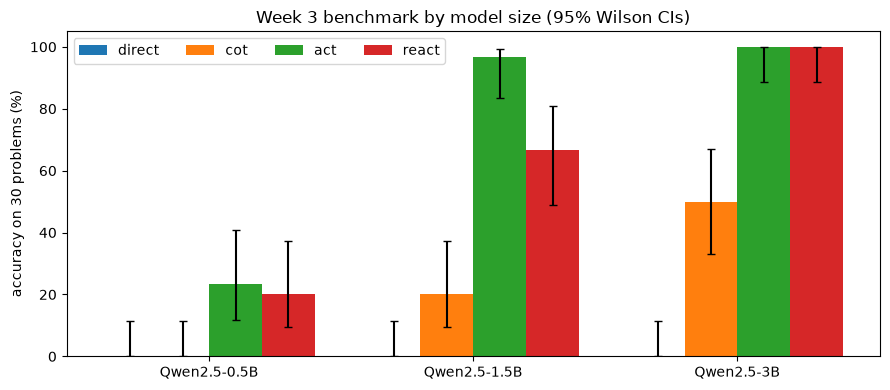

In [19]:
fig, ax = plt.subplots(figsize=(9, 4))
w = 0.2
for i, mode in enumerate(MODES):
    xs, ys, err = [], [], [[], []]
    for j, (size, R) in enumerate(data.items()):
        rs = [r for r in R if r["mode"] == mode]
        if not rs:
            continue
        k, n = sum(r["correct"] for r in rs), len(rs)
        lo, hi = wilson_ci(k, n)
        xs.append(j + (i - 1.5) * w); ys.append(k / n * 100); err[0].append((k / n - lo) * 100); err[1].append((hi - k / n) * 100)
    ax.bar(xs, ys, w, yerr=err, capsize=3, label=mode)
ax.set_xticks(range(len(data))); ax.set_xticklabels([f"Qwen2.5-{s}" for s in data])
ax.set_ylabel("accuracy on 30 problems (%)"); ax.set_ylim(0, 105); ax.legend(ncol=4)
ax.set_title("Week 3 benchmark by model size (95% Wilson CIs)")
plt.tight_layout()
if ON_COLAB:
    plt.savefig(Path(RESULTS) / "accuracy_by_size.png", dpi=130)
plt.show()

**What to look at:** the calculator does the work. Act-only climbs from 23% to 97% to 100% with size, while without a tool even 3B reaches only 50% (CoT) and direct answers stay at 0%.

### The confirmatory question: ReAct vs Act-only, paired

Both modes ran on the same 30 problems, so the comparison is paired: count the problems only one mode solved (the discordant pairs), test them with an exact McNemar test, and put a bootstrap CI on the difference.

In [20]:
rows = []
for size, R in data.items():
    a = [r["correct"] for r in sorted(R, key=lambda r: r["pid"]) if r["mode"] == "react"]
    b = [r["correct"] for r in sorted(R, key=lambda r: r["pid"]) if r["mode"] == "act"]
    eff, lo, hi = paired_bootstrap_ci(np.array(a, float), np.array(b, float))
    only_react, only_act = discordant(np.array(a, float), np.array(b, float))
    tok = lambda m: np.mean([r["tokens_in"] + r["tokens_out"] for r in R if r["mode"] == m])
    rows.append({"size": size, "ReAct": f"{np.mean(a):.0%}", "Act-only": f"{np.mean(b):.0%}",
                 "ReAct − Act (pts)": f"{eff * 100:+.1f}", "95% CI": f"{lo * 100:+.1f} to {hi * 100:+.1f}",
                 "only ReAct solved": only_react, "only Act solved": only_act,
                 "McNemar p": round(mcnemar_exact(only_react, only_act), 3),
                 "tokens ReAct / Act": f"{tok('react') / tok('act'):.2f}×"})
pd.DataFrame(rows).set_index("size")

,ReAct,Act-only,ReAct − Act (pts),95% CI,only ReAct solved,only Act solved,McNemar p,tokens ReAct / Act
size,,,,,,,,
0.5B,20%,23%,-3.3,-16.7 to +10.0,2,3,1.000,1.26×
1.5B,67%,97%,-30.0,-50.0 to -13.3,1,10,0.012,1.43×
3B,100%,100%,+0.0,+0.0 to +0.0,0,0,1.000,1.89×


**Result:** ReAct did not beat Act-only at any size. At 0.5B the two are level (20% vs 23%). At **1.5B ReAct is 30 points worse** (67% vs 97%, CI −50 to −13, p = 0.012): the written reasoning introduced errors. At 3B both reach 100%, so there is no headroom, and ReAct costs 1.89× the tokens.

### Cost against accuracy

Accuracy alone hides cost. The committed figures put both on one chart:

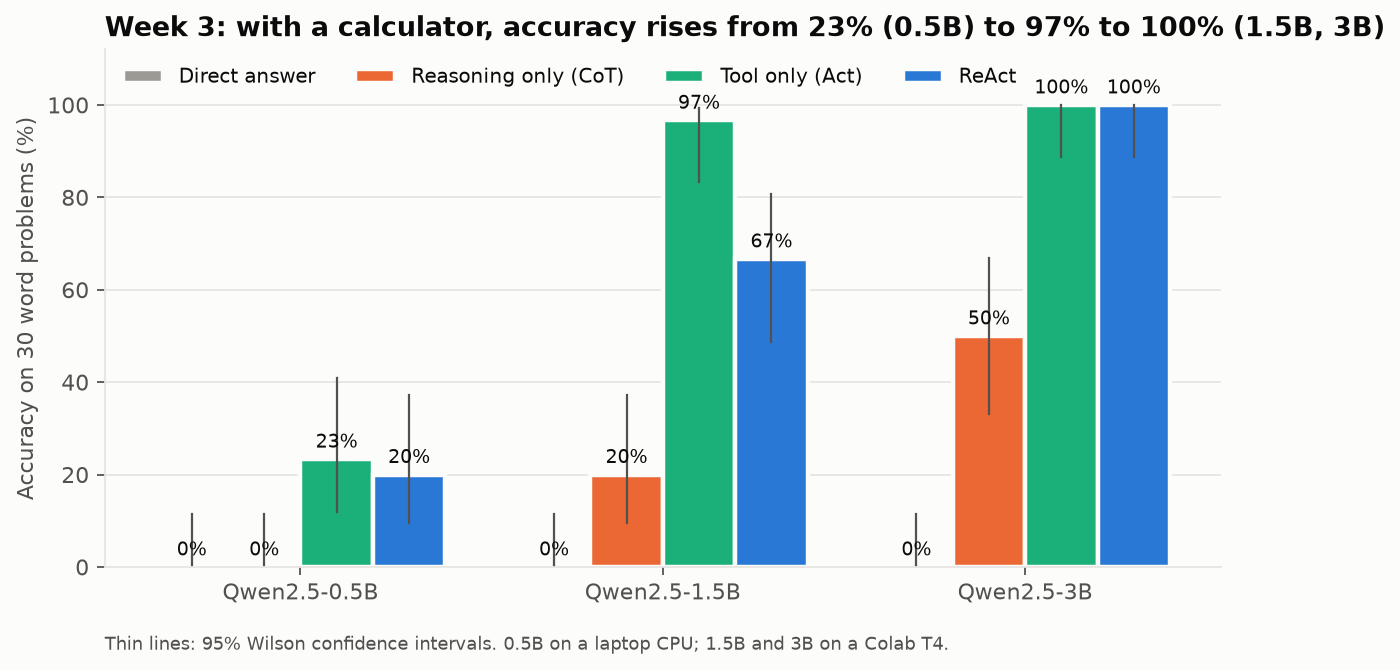

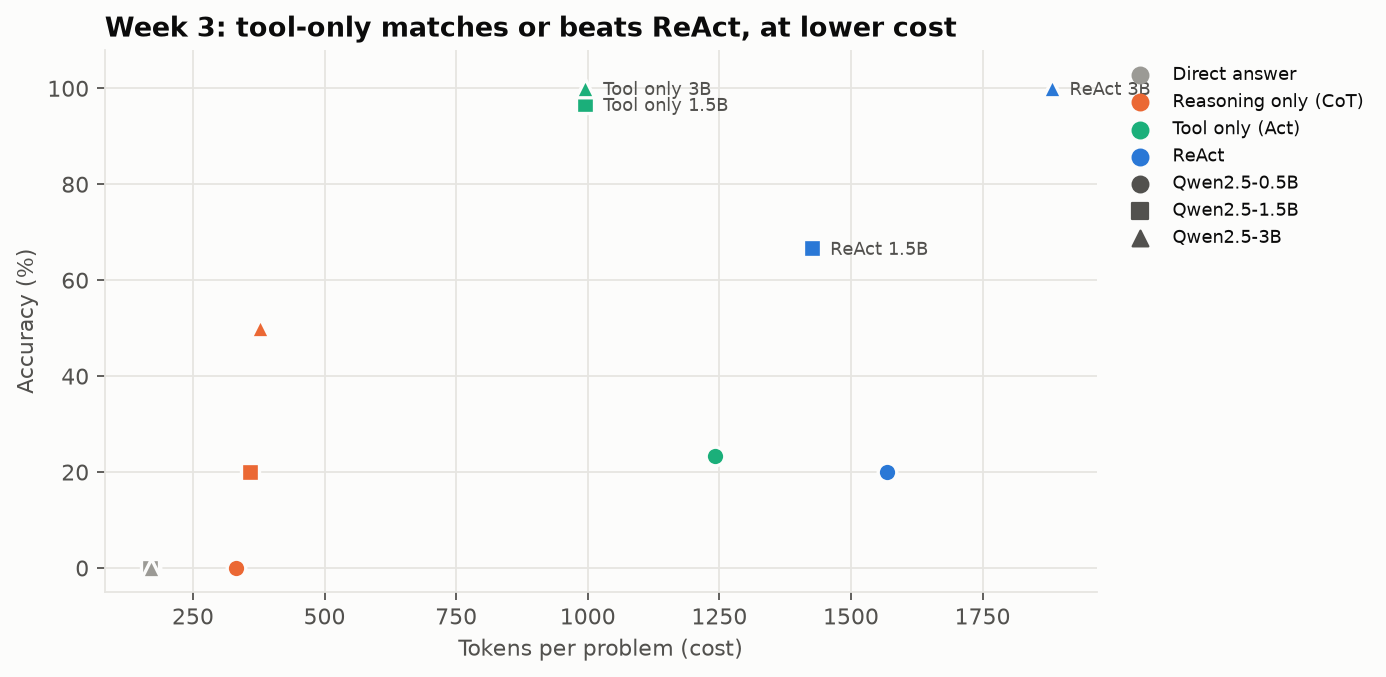

In [21]:
for name in ("week3_accuracy_by_size", "week3_cost_vs_accuracy"):
    f = Path("results/figures") / f"{name}.png"
    if f.exists():
        display(Image(str(f), width=720))

On cost and accuracy together, Act-only dominates: it is at least as accurate as ReAct at every size and uses fewer tokens.

## 7. How do the runs fail?

Each wrong run gets one failure type (the categories later fixed in the Week 4 protocol).

In [22]:
show(run_react_bench.failure_type)
ft = pd.DataFrame([dict(size=size, mode=r["mode"], failure=run_react_bench.failure_type(r))
                   for size, R in data.items() for r in R])
pd.crosstab([ft["size"], ft["mode"]], ft["failure"]).loc[[(s, m) for s in data for m in MODES]]

def failure_type(row: dict) -> str:
    """Week 4 protocol failure categories (section 5)."""
    if row["correct"]:
        return "correct"
    traj = row.get("trajectory", "")
    if "Unknown action" in traj:
        return "invented tool"
    if any(seg.count("Action:") > 1 for seg in traj.split("Observation:")[:-1]):
        return "multiple actions per step"
    if row["answer"] is None:
        return {"max_steps": "step limit", "invalid_action": "invalid action"}.get(row["status"], "no answer")
    obs = [o for o in row.get("observations", []) if not o.startswith("Error")]
    if obs and to_number(obs[-1]) is not None and to_number(row["answer"]) != to_number(obs[-1]):
        return "ignored or overrode observation"
    return "misread problem / wrong expression"

failure      correct  ignored or overrode observation  invented tool  \
size mode                                                              
0.5B direct        0                                0              0   
     cot           0                                0              0   
     act           7                                0              0   
     react         6                                3              1   
1.5B direct        0                                0              0   
     cot           6                                0              0   
     act          29                                0              0   
     react        20                                0              5   
3B   direct        0                                0              0   
     cot          15                                0              0   
     act          30                                0              0   
     react        30                                0              0   

failure      misread problem / wrong expression  no answer  step limit  
size mode                                                               
0.5B direct                                  30          0           0  
     cot                                     30          0           0  
     act                                     20          0           3  
     react                                   20          0           0  
1.5B direct                                  16         14           0  
     cot                                     21          3           0  
     act                                      1          0           0  
     react                                    5          0           0  
3B   direct                                  30          0           0  
     cot                                     14          1           0  
     act                                      0          0           0  
     react                                    0          0           0

Without a calculator, wrong answers are usually near misses: the plan was right and the arithmetic slipped. With a calculator, wrong answers come from a wrong plan.

In [23]:
def rel_err(r):
    v = react_agent.to_number(r["answer"])
    return None if v is None else abs(v - r["gold"]) / abs(r["gold"])

rows = []
for size, R in data.items():
    for mode in MODES:
        errs = [e for r in R if r["mode"] == mode and not r["correct"] and (e := rel_err(r)) is not None]
        rows.append(dict(size=size, mode=mode, wrong_with_a_number=len(errs),
                         median_error=f"{np.median(errs):.1%}" if errs else ""))
pd.DataFrame(rows).pivot(index="mode", columns="size", values="median_error").loc[MODES]

size,0.5B,1.5B,3B
mode,,,
direct,93.7%,89.1%,21.1%
cot,4.9%,1.1%,0.5%
act,88.8%,200.0%,
react,96.8%,93.3%,


### Where ReAct lost at 1.5B

All ten ReAct failures at 1.5B came from two templates. Per template:

In [24]:
R15 = data["1.5B"]
pd.crosstab(pd.Series([r["template"] for r in R15 if r["mode"] in ("act", "react")], name="template"),
            pd.Series([r["mode"] for r in R15 if r["mode"] in ("act", "react")], name="mode"),
            values=[r["correct"] for r in R15 if r["mode"] in ("act", "react")], aggfunc="sum").astype(int)

mode,act,react
template,,
charity,4,5
crates,5,5
library,5,0
salary,5,5
train,5,0
warehouse,5,5


Two full trajectories show the two failure patterns. In **train**, the Thought drops "for N days" and the model adds the two distances. In **library**, the model invents tools such as `add[...]` and does arithmetic in its head.

In [25]:
def transcript(r):
    p = PROBLEMS[r["pid"]]
    print(f"[{r['mode']}, {r['template']}] {p['question']}")
    print(f"gold {r['gold']}, answer {r['answer']} → {run_react_bench.failure_type(r)}\n")
    print(r["trajectory"].strip(), "\n" + "─" * 80)

for template in ("train", "library"):
    r = next(r for r in R15 if r["mode"] == "react" and r["template"] == template and not r["correct"])
    transcript(r)

[react, train] A train travels 577 km each day for 46 days, then another 647 km. How many km does it travel in total?
gold 27189, answer 1224 → misread problem / wrong expression

Thought: To find out how many kilometers the train travels in total, we need to add the distance traveled during the first part (577 km) to the distance traveled during the second part (647 km).
Action: calculate[577 + 647]
Observation: 1224
Thought: The train travels a total of 1224 kilometers.
Action: finish[1224] 
────────────────────────────────────────────────────────────────────────────────
[react, library] A library has 6,134 books. It buys 20 boxes of 36 books each and then donates 586 books. How many books does it have now?
gold 6268, answer calculate[6134 + 720 - 586] → invented tool

Thought: To find out how many books the library has after buying new ones and donating some, we need to follow these steps:
1. Calculate the total number of books bought (number of boxes times the number of books per b

The same train problem with Act-only, which solved it:

In [26]:
r_bad = next(r for r in R15 if r["mode"] == "react" and r["template"] == "train" and not r["correct"])
transcript(next(r for r in R15 if r["mode"] == "act" and r["pid"] == r_bad["pid"]))

[act, train] A train travels 577 km each day for 46 days, then another 647 km. How many km does it travel in total?
gold 27189, answer 27189 → correct

Action: calculate[577 * 46]
Observation: 26542
Action: calculate[26542 + 647]
Observation: 27189
Action: finish[27189] 
────────────────────────────────────────────────────────────────────────────────


## 8. Reading the result honestly

Thirty problems give low statistical power. The Week 4 audit found this sample has about 10% power to detect a real ReAct vs Act difference, and the 1.5B gap comes from just two templates. Treat this as a pilot. Its most useful output is the discordance (the share of problems where the two modes disagree), which sized the larger, held-out, pre-registered Week 4 protocol.

To run more problems with the same templates: `!python src/run_react_bench.py --model ... --n-per 50 --out results/week3/big.jsonl` (300 problems). That isn't the full protocol, which also needs held-out templates the prompt never showed.

## 9. Save and download (Colab only)

Saves a copy of this notebook with its outputs next to the results, then downloads a zip of `results/week3/`. On your laptop, unzip into `results/` in the repo. With Drive on, the files are also in `MyDrive/AI-Engineering/week3_gpu`.

In [27]:
if ON_COLAB:
    try:   # save this notebook with every output, so the results and graphs are readable on GitHub
        from google.colab import _message
        nb = _message.blocking_request("get_ipynb", timeout_sec=60)["ipynb"]
        with open(os.path.join(RESULTS, "week3_colab_executed.ipynb"), "w") as f:
            json.dump(nb, f)
        print("saved the executed notebook")
    except Exception as e:
        print("could not save the executed notebook:", e, "\nUse File → Download → Download .ipynb instead.")
else:
    print("Not on Colab: nothing to save. This notebook already reads from results/week3/ in the repo.")

Not on Colab: nothing to save. This notebook already reads from results/week3/ in the repo.


In [28]:
if ON_COLAB:
    !cd results && zip -qr /content/week3_results.zip week3/
    from google.colab import files
    files.download("/content/week3_results.zip")